# Emulator accuracy validation

Validates a lightweight JAX/NPZ `cmb_baryon_emu` spectrum emulator against the bundled
held-out fixture in `data/validation_all_spectra_500.h5`. The rows come from the tail of
the full training HDF5, never seen in training since `train_emulator.py` reads `[:ntrain]`.

Shows the **raw relative error** `|pred - truth| / |truth|` vs multipole.

In [1]:
from pathlib import Path

import numpy as np
import h5py
import hdf5plugin  # noqa: F401  registers the Zstd decompressor
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})

## Configuration

In [7]:
SPECTRUM = 'EE_lensed'  # one of TT/EE/TE _lensed/_unlensed
MODEL_NAME = SPECTRUM.lower()
NTEST = 500             # max rows to read from the validation fixture

# Works whether the notebook is launched from the repo root or notebooks/.
REPO_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA_FILE = REPO_ROOT / 'data' / 'validation_all_spectra_500.h5'

print('spectrum :', SPECTRUM)
print('model    :', MODEL_NAME)
print('data     :', DATA_FILE)

spectrum : EE_lensed
model    : ee_lensed
data     : /cluster/work/refregier/alexree/local_packages/cmb_baryon_emu/data/validation_all_spectra_500.h5


## 1. Load lightweight JAX model + held-out data

In [8]:
from cmb_baryon_emu import JaxNpzModel, structured_params_to_matrix

model = JaxNpzModel.from_package(MODEL_NAME)
print('parameter_names:', model.parameter_names)

with h5py.File(DATA_FILE, 'r') as f:
    if SPECTRUM not in f:
        available = [key for key in f.keys() if key not in {'params', 'ell'}]
        raise KeyError(f'{DATA_FILE} contains spectra {available}, not {SPECTRUM!r}')

    n_test = min(NTEST, f['params'].shape[0])
    raw_params = f['params'][-n_test:]
    test_truth = f[SPECTRUM][-n_test:, :]
    ell = f['ell'][:]

param_names = list(raw_params.dtype.names)
params_mat = structured_params_to_matrix(raw_params, param_names)
print('params:', params_mat.shape, ' scaler features:', model.scaler_mean_in.shape[0])
print('test samples:', test_truth.shape[0], ' output dim:', test_truth.shape[1])

parameter_names: ['omega_cdm', 'omega_b', 'ln10As', 'n_s', 'tau', 'h', 'log10Mc', 'Theta_co', 'mu', 'delta', 'eta', 'deta', 'Nstar', 'fb']
params: (500, 196)  scaler features: 196
test samples: 500  output dim: 9999


In [9]:
print('params_mat shape:', params_mat.shape)
print('first sample, first 14 tiled inputs:', params_mat[0, :14])

params_mat shape: (500, 196)
first sample, first 14 tiled inputs: [ 0.12081658  0.02363167  3.00106045  0.95051574  0.03890712  0.68833675
 13.98052646  0.37659322  2.129741    6.40813301  0.14263595  0.33276551
  0.03430806  0.19977235]


In [10]:
pred = model.predict_matrix(params_mat)
n_out = min(pred.shape[1], test_truth.shape[1])
pred, test_truth = pred[:, :n_out], test_truth[:, :n_out]
ell = ell[:n_out]
print('pred:', pred.shape, ' truth:', test_truth.shape)

pred: (500, 9999)  truth: (500, 9999)


## 2. Raw relative error vs multipole

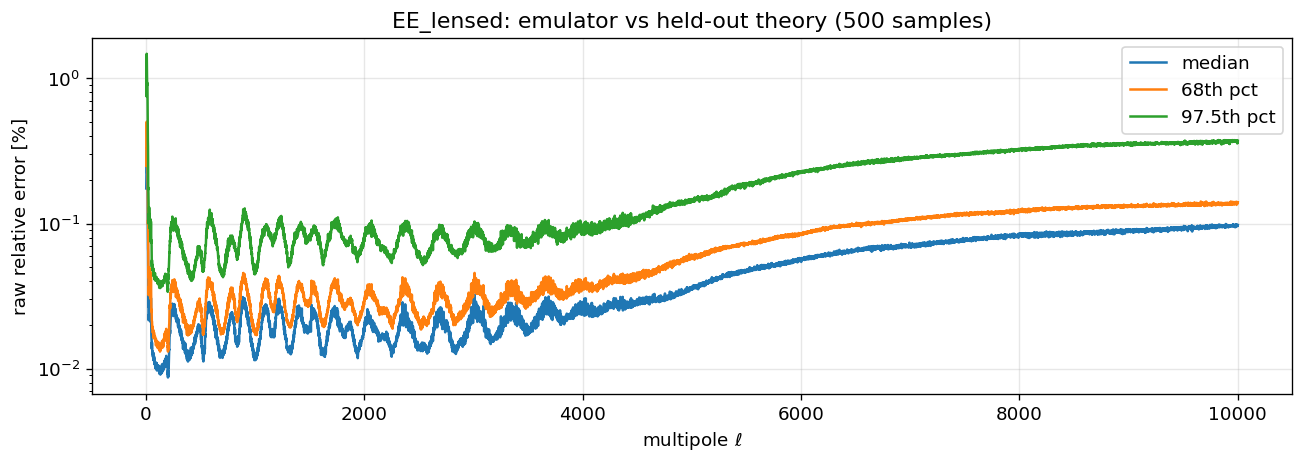

median rel err: 0.035%   97.5th pct: 0.236%


In [11]:
eps = 1e-40
rel_err = np.abs((pred - test_truth) / (np.abs(test_truth) + eps))
p50, p68, p95 = np.percentile(rel_err, [50, 68, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ell, 100 * p50, label='median')
ax.plot(ell, 100 * p68, label='68th pct')
ax.plot(ell, 100 * p95, label='97.5th pct')
ax.set_xlabel(r'multipole $\ell$')
ax.set_ylabel('raw relative error [%]')
ax.set_title(f'{SPECTRUM}: emulator vs held-out theory ({rel_err.shape[0]} samples)')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'median rel err: {100*np.median(rel_err):.3f}%   97.5th pct: {100*np.percentile(rel_err, 97.5):.3f}%')